In [1]:
import numpy as np
import time
from datetime import timedelta
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.utils import shuffle
from sklearn.utils.class_weight import compute_class_weight
from keras.utils import to_categorical
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, GlobalMaxPooling1D, Flatten, Dense, Dropout, Input, BatchNormalization, GlobalAveragePooling1D, Embedding
from keras.optimizers import Adam

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from tensorflow.keras.regularizers import l2

from tensorflow.keras.layers import LSTM

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
#from google.colab import drive
#drive.mount('/content/drive')

Mounted at /content/drive


# Data shtuff

In [2]:
path = r"datasets\without duplicates\withoutduplicates_combined_7sec.csv"
df = pd.read_csv(path)

In [3]:
shuffled_df = shuffle(df).reset_index(drop = True)
display(shuffled_df)

print(df.shape)

,1_0,2_0,3_0,4_0,5_0,6_0,7_0,8_0,9_0,10_0,...,35_139,36_139,37_139,38_139,39_139,40_139,41_139,42_139,43_139,target
0,18.0,1.0,31.0,0.0,4.0,100.0,1.437635,6.042819,7.548350,9.775482,...,-0.925859,0.006497,0.000000,1.000000,182.370600,-43.836050,7.879723,187.730470,14.0,0
1,22.0,1.0,65.0,0.0,5.0,75.0,1.027959,9.091613,3.642587,9.847973,...,0.012275,0.808357,0.000000,1.000000,2.360229,-72.020355,5.639251,72.279340,0.0,1
2,19.0,1.0,55.0,1.0,7.0,67.0,0.093903,5.723734,6.901712,8.966804,...,0.813819,0.531631,0.000000,1.000000,248.314150,-25.801262,8.736242,249.803820,0.0,1
3,18.0,1.0,16.0,0.0,5.0,75.0,0.965838,6.266208,7.104076,9.521875,...,-0.925266,0.153088,0.000000,1.000000,162.119750,-40.552780,2.460334,167.132860,28.0,0
4,17.0,1.0,5.0,0.0,4.0,100.0,1.234809,4.874329,8.701764,10.050101,...,0.826538,0.506483,0.000000,1.000000,244.838150,-27.502733,7.509446,246.492420,14.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9132,20.0,1.0,43.0,1.0,5.0,53.0,-0.142011,4.274377,8.364823,9.394718,...,0.622077,0.753771,0.000000,1.000000,28.078125,-22.781250,-0.515625,36.161198,0.0,0
9133,21.0,1.0,91.0,2.0,4.0,100.0,-0.715866,5.564125,7.601591,9.447546,...,0.853609,0.413000,0.000000,1.000000,231.771910,-37.025158,-2.543650,234.724410,0.0,0
9134,21.0,0.0,150.0,8.0,6.0,168.0,-0.661917,8.770580,4.359387,9.816591,...,0.693300,0.489250,0.000000,1.000000,251.493100,-63.724840,-3.070977,259.459170,143.0,1
9135,22.0,1.0,98.0,33.0,4.0,100.0,0.349172,7.985555,5.207587,9.539915,...,-0.699706,0.542243,0.174533,1.015117,105.755310,-55.405518,2.482639,119.415750,14.0,1


(9137, 6021)


In [ ]:
df.info()

In [ ]:
df.describe()

In [ ]:
#shapes = pd.DataFrame({
#    "DataFrame": ["original", "1 sec", "3 secs", "5 secs", "7 secs"],
#    "Shape": [df0.shape, df1.shape, df3.shape, df5.shape, df7.shape],
#    "Total Elements": [df0.shape[0] * df0.shape[1], df1.shape[0] * df1.shape[1],
#                       df3.shape[0] * df3.shape[1], df5.shape[0] * df5.shape[1],
#                       df7.shape[0] * df7.shape[1]]
#})

#display(shapes)

,DataFrame,Shape,Total Elements
0,original,"(1540372, 43)",66235996
1,1 sec,"(77017, 841)",64771297
2,3 secs,"(25671, 2521)",64716591
3,5 secs,"(15402, 4201)",64703802
4,7 secs,"(11002, 5881)",64702762


In [4]:
target_distribution = shuffled_df['target'].value_counts(normalize=True)
print(target_distribution)

target
1    0.543942
0    0.456058
Name: proportion, dtype: float64


In [5]:
def data_splitting(df):
    X = df.drop(columns = ["target"])
    y = df["target"]

    # Standardize the data
    #scaler = StandardScaler()
    scaler = MinMaxScaler()
    X = scaler.fit_transform(X)

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = y, shuffle = True)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=42, stratify = y_train, shuffle = True)


    # Standardize the data
    #scaler = StandardScaler()
    #X_train = scaler.fit_transform(X_train)
    #X_test = scaler.transform(X_test)
    #X_val = scaler.transform(X_val)

    #print(X_train.shape, y_train.shape)
    #print(X_val.shape, y_val.shape)
    #print(X_test.shape, y_test.shape)

    shapes_df = pd.DataFrame({
        'Set': ['Training Set', 'Validation Set', 'Test Set'],
        'Features Shape': [X_train.shape, X_val.shape, X_test.shape],
        'Labels Shape': [y_train.shape, y_val.shape, y_test.shape]
                })

    display(shapes_df)

    return X_train, y_train, X_val, y_val, X_test, y_test




In [6]:
X_train, y_train, X_val, y_val, X_test, y_test = data_splitting(shuffled_df)

,Set,Features Shape,Labels Shape
0,Training Set,"(6578, 6020)","(6578,)"
1,Validation Set,"(731, 6020)","(731,)"
2,Test Set,"(1828, 6020)","(1828,)"


In [7]:
# Compute class weights
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = dict(enumerate(class_weights))
print(class_weights_dict)

{0: 1.0963333333333334, 1: 0.9192286193404137}


# Models

## FNN

In [149]:
def fnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test):
    # Assuming X_train is already defined
    input_shape = X_train.shape[1]

    # Define early stopping with patience
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001)

    # Build the model
    fnn_model = Sequential()
    fnn_model.add(Input(shape=(input_shape,)))
    fnn_model.add(Dense(512, activation='relu'))
    fnn_model.add(Dropout(0.3))
    fnn_model.add(Dense(256, activation='relu'))
    fnn_model.add(Dropout(0.3))
    fnn_model.add(Dense(128, activation='relu', kernel_regularizer=l2(0.01)))
    fnn_model.add(Dropout(0.5))
    fnn_model.add(Dense(64, activation='relu', kernel_regularizer=l2(0.01)))
    fnn_model.add(Dropout(0.6))
    fnn_model.add(Dense(32, activation='relu'))
    fnn_model.add(Dropout(0.6))
    fnn_model.add(Dense(1, activation='sigmoid'))
    fnn_model.summary()

    # Compile the model
    fnn_model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

    # Train the model
    start_time_fnn = time.time()
    fnn_history = fnn_model.fit(X_train, y_train
                        ,validation_data = (X_val, y_val)
                        ,epochs = 100
                        ,batch_size = 32
                        ,callbacks = [reduce_lr, early_stopping]
                        ,class_weight = class_weights_dict
                        )
    end_time_fnn = time.time()


    # Calculate the elapsed time
    training_time_fnn = end_time_fnn - start_time_fnn
    print(f"FNN Model training time: {training_time_fnn:.2f} seconds")
    # Convert time to minutes, seconds, and milliseconds
    td = timedelta(seconds=training_time_fnn)
    milliseconds = int(training_time_fnn * 1000) % 1000
    print(f"FNN Model training time: {td.seconds // 60} minutes, {td.seconds % 60} seconds, and {milliseconds} milliseconds")


    # Predict on test data
    fnn_y_pred_prob = fnn_model.predict(X_test)
    fnn_y_pred = (fnn_y_pred_prob > 0.5).astype(int)


    # result calculation
    cm = confusion_matrix(y_test, fnn_y_pred)
    cr = classification_report(y_test, fnn_y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, fnn_y_pred).ravel()

    precision = precision_score(y_test, fnn_y_pred)
    recall = recall_score(y_test, fnn_y_pred)
    f1 = f1_score(y_test, fnn_y_pred)
    accuracy = accuracy_score(y_test, fnn_y_pred)
    specificity = tn / (tn + fp)

    # ROC AUC Curve
    fpr, tpr, thresholds = roc_curve(y_test, fnn_y_pred_prob)
    roc_auc = roc_auc_score(y_test, fnn_y_pred_prob)

    # Precision-Recall Curve
    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, fnn_y_pred_prob)
    avg_precision = average_precision_score(y_test, fnn_y_pred_prob)

    return [fnn_history, cm, cr, accuracy, precision, recall,
            f1, specificity, roc_auc, avg_precision, fpr, tpr, thresholds,
            precision_vals, recall_vals, pr_thresholds]


In [150]:
[fnn_history, fnn_cm, fnn_cr, fnn_accuracy, fnn_precision, fnn_recall,
    fnn_f1, fnn_specificity, fnn_roc_auc, fnn_avg_precision, fnn_fpr, fnn_tpr, fnn_thresholds,
    fnn_precision_vals, fnn_recall_vals, fnn_pr_thresholds] = fnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test)


Model: "sequential_28"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_45 (Dense)            (None, 512)               3082752   
                                                                 
 dropout_101 (Dropout)       (None, 512)               0         
                                                                 
 dense_46 (Dense)            (None, 256)               131328    
                                                                 
 dropout_102 (Dropout)       (None, 256)               0         
                                                                 
 dense_47 (Dense)            (None, 128)               32896     
                                                                 
 dropout_103 (Dropout)       (None, 128)               0         
                                                                 
 dense_48 (Dense)            (None, 64)              

## CNN

In [36]:
def cnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test):
    # Reshape data for Conv1D
    cnn_X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
    cnn_X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))
    cnn_X_val = X_val.reshape((X_val.shape[0], X_val.shape[1], 1))


    # Define early stopping with patience
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001)


    # Build and train the CNN model
    cnn_model = Sequential([
        Conv1D(filters=64, kernel_size=7, activation='relu', input_shape=(cnn_X_train.shape[1], 1), kernel_regularizer=l2(0.01)),
        #BatchNormalization(),
        #MaxPooling1D(pool_size=5),
        Dropout(0.3),

        Conv1D(filters=64, kernel_size=7, activation='relu', kernel_regularizer=l2(0.01)),
        #BatchNormalization(),
        #MaxPooling1D(pool_size=5),
        #GlobalMaxPooling1D(),
        Dropout(0.6),

        #Conv1D(filters=128, kernel_size=7, activation='relu', kernel_regularizer=l2(0.01)),
        #BatchNormalization(),
        #MaxPooling1D(pool_size=5),
        Dropout(0.6),
        #GlobalMaxPooling1D(),

        Flatten(),
        Dense(128, activation='relu'),# kernel_regularizer=l2(0.01)),
        Dropout(0.6),
        #Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
        #Dropout(0.5),
        #Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
        #Dropout(0.5),
        Dense(32, activation='relu'),# kernel_regularizer=l2(0.01)),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])
    cnn_model.summary()

    cnn_model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

    start_time_cnn = time.time()
    cnn_history = cnn_model.fit(cnn_X_train, y_train
                                ,validation_data=(cnn_X_val, y_val)
                                ,epochs=100
                                ,batch_size=32
                                ,callbacks=[early_stopping, reduce_lr]
                                ,class_weight = class_weights_dict
                                )
    end_time_cnn = time.time()

    # Calculate the elapsed time
    training_time_cnn = end_time_cnn - start_time_cnn
    print(f"FNN Model training time: {training_time_cnn:.2f} seconds")
    # Convert time to minutes, seconds, and milliseconds
    td = timedelta(seconds=training_time_cnn)
    milliseconds = int(training_time_cnn * 1000) % 1000
    print(f"FNN Model training time: {td.seconds // 60} minutes, {td.seconds % 60} seconds, and {milliseconds} milliseconds")

    # Evaluate CNN model
    cnn_y_pred_prob = cnn_model.predict(cnn_X_test)
    cnn_y_pred = (cnn_y_pred_prob > 0.5).astype(int)

    # result calculation
    cm = confusion_matrix(y_test, cnn_y_pred)
    cr = classification_report(y_test, cnn_y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, cnn_y_pred).ravel()

    precision = precision_score(y_test, cnn_y_pred)
    recall = recall_score(y_test, cnn_y_pred)
    f1 = f1_score(y_test, cnn_y_pred)
    accuracy = accuracy_score(y_test, cnn_y_pred)
    specificity = tn / (tn + fp)


    # ROC AUC Curve
    fpr, tpr, thresholds = roc_curve(y_test, cnn_y_pred_prob)
    roc_auc = roc_auc_score(y_test, cnn_y_pred_prob)

    # Precision-Recall Curve
    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, cnn_y_pred_prob)
    avg_precision = average_precision_score(y_test, cnn_y_pred_prob)

    return [cnn_history, cm, cr, accuracy, precision, recall,
            f1, specificity, roc_auc, avg_precision, fpr, tpr, thresholds,
            precision_vals, recall_vals, pr_thresholds]


In [37]:
#cnn model
[cnn_history, cnn_cm, cnn_cr, cnn_accuracy, cnn_precision, cnn_recall,
    cnn_f1, cnn_specificity, cnn_roc_auc, cnn_avg_precision, cnn_fpr, cnn_tpr, cnn_thresholds,
    cnn_precision_vals, cnn_recall_vals, cnn_pr_thresholds] = cnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test)

Model: "sequential_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d_15 (Conv1D)          (None, 6014, 64)          512       
                                                                 
 dropout_25 (Dropout)        (None, 6014, 64)          0         
                                                                 
 conv1d_16 (Conv1D)          (None, 6008, 64)          28736     
                                                                 
 dropout_26 (Dropout)        (None, 6008, 64)          0         
                                                                 
 dropout_27 (Dropout)        (None, 6008, 64)          0         
                                                                 
 flatten_6 (Flatten)         (None, 384512)            0         
                                                                 
 dense_17 (Dense)            (None, 128)              

## LSTM

In [10]:
def lstm_model_definition(X_train, y_train, X_val, y_val, X_test, y_test):

    #X_train_lstm = X_train.reshape(X_train.shape[0], 1, X_train.shape[1])
    #X_test_lstm = X_test.reshape(X_test.shape[0], 1, X_test.shape[1])
    #X_val_lstm = X_val.reshape(X_val.shape[0], 1, X_val.shape[1])

    # One-hot encode the labels
    y_train_encoded = to_categorical(y_train, num_classes=2)
    y_val_encoded = to_categorical(y_val, num_classes=2)
    y_test_encoded = to_categorical(y_test, num_classes=2)
    #y_train = pd.get_dummies(y_train).values
    #y_test = pd.get_dummies(y_test).values
    #y_val = pd.get_dummies(y_val).values

    # Define early stopping with patience
    early_stopping = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001)

    # LSTM
    model = Sequential()
    #model.add(Input(shape = (X_train_lstm.shape[1], X_train_lstm.shape[2])))

    #model.add(LSTM(256, return_sequences=True))
    #model.add(Dropout(0.5))
    #model.add(BatchNormalization())

    #model.add(LSTM(128, return_sequences=True))
    #model.add(Dropout(0.5))
    #model.add(BatchNormalization())

    #model.add(LSTM(64, return_sequences=True))
    #model.add(Dropout(0.5))
    #model.add(BatchNormalization())

    #model.add(LSTM(8, kernel_regularizer=l2(0.01)))
    #model.add(Dropout(0.5))
    #model.add(BatchNormalization())

    model.add(Embedding(5000,100, input_length=X_train.shape[1]))
    model.add(Dropout(0.5))
    model.add(LSTM(100))
    model.add(Dense(2, activation='softmax'))

    model.summary()

    # Compile the model
    model.compile(optimizer = "adam", loss = "binary_crossentropy", metrics = ["accuracy","mae","mse"])

    # Train the model
    start_time_lstm = time.time()
    lstm_history = model.fit(X_train, y_train_encoded
                            ,epochs=100
                            ,batch_size=128
                            #,verbose = 1
                            ,validation_data=(X_val, y_val_encoded)
                            #,callbacks = [reduce_lr, early_stopping]
                            #,class_weight = class_weights_dict
                             )
    end_time_lstm = time.time()

    # Calculate the elapsed time
    training_time_lstm = end_time_lstm - start_time_lstm
    print(f"LSTM Model training time: {training_time_lstm:.2f} seconds")
    # Convert time to minutes, seconds, and milliseconds
    td = timedelta(seconds=training_time_lstm)
    milliseconds = int(training_time_lstm * 1000) % 1000
    print(f"LSTM Model training time: {td.seconds // 60} minutes, {td.seconds % 60} seconds, and {milliseconds} milliseconds")


    #lstm_y_pred_prob = model.predict(X_test_lstm)
    #lstm_y_pred = (lstm_y_pred_prob > 0.5).astype(int)

    # Make predictions on the test set
    lstm_y_pred_prob = model.predict(X_test)
    lstm_y_pred = np.argmax(lstm_y_pred_prob, axis=1)
    y_test_labels = np.argmax(y_test_encoded, axis=1)

    # result calculation
    cm = confusion_matrix(y_test_labels, lstm_y_pred)
    cr = classification_report(y_test_labels, lstm_y_pred)

    tn, fp, fn, tp = cm.ravel()

    precision = precision_score(y_test_labels, lstm_y_pred)
    recall = recall_score(y_test_labels, lstm_y_pred)
    f1 = f1_score(y_test_labels, lstm_y_pred)
    accuracy = accuracy_score(y_test_labels, lstm_y_pred)
    specificity = tn / (tn + fp)

    # ROC AUC Curve
    fpr, tpr, thresholds = roc_curve(y_test_labels, lstm_y_pred_prob[:, 1])  # Use probabilities for positive class
    roc_auc = roc_auc_score(y_test_labels, lstm_y_pred_prob[:, 1])  # Use probabilities for positive class

    # Precision-Recall Curve
    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test_labels, lstm_y_pred_prob[:, 1])  # Use probabilities for positive class
    avg_precision = average_precision_score(y_test_labels, lstm_y_pred_prob[:, 1])  # Use probabilities for positive class

    return [lstm_history, cm, cr, accuracy, precision, recall,
            f1, specificity, roc_auc, avg_precision, fpr, tpr, thresholds,
            precision_vals, recall_vals, pr_thresholds]


In [11]:
#lstm model
[lstm_history, lstm_cm, lstm_cr, lstm_accuracy, lstm_precision, lstm_recall,
    lstm_f1, lstm_specificity, lstm_roc_auc, lstm_avg_precision, lstm_fpr, lstm_tpr, lstm_thresholds,
    lstm_precision_vals, lstm_recall_vals, lstm_pr_thresholds] = lstm_model_definition(X_train, y_train, X_val, y_val, X_test, y_test)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
11/52 ━━━━━━━━━━━━━━━━━━━━ 17:16 25s/step - accuracy: 0.5456 - loss: 0.6904 - mae: 0.4939 - mse: 0.2506

KeyboardInterrupt: 

# Results

## FNN

In [151]:
print("FNN model:")
print("Accuracy: ", fnn_accuracy)
print("Precision: ", fnn_precision)
print("Recall: ", fnn_recall)
print("F1 score: ", fnn_f1)
print("Specificity: ", fnn_specificity)
print("AUC-ROC:", fnn_roc_auc)

FNN model:
Accuracy:  0.812363238512035
Precision:  0.8926417370325693
Recall:  0.744466800804829
F1 score:  0.811848601206802
Specificity:  0.8932853717026379
AUC-ROC: 0.8958601730285792


In [152]:
print("fnn_avg_precision: ", fnn_avg_precision)
print("fnn_fpr: ", fnn_fpr)
print("fnn_tpr: ", fnn_tpr)
print("fnn_thresholds: ", fnn_thresholds)
print("fnn_precision_vals: ", fnn_precision_vals)
print("fnn_recall_vals: ", fnn_recall_vals)
print("fnn_pr_thresholds: ", fnn_pr_thresholds)

fnn_avg_precision:  0.9227917924282092
fnn_fpr:  [0.         0.00119904 0.00119904 0.00119904 0.00119904 0.00119904
 0.00119904 0.00119904 0.00119904 0.00119904 0.00119904 0.00119904
 0.00119904 0.00239808 0.00239808 0.00239808 0.00239808 0.00359712
 0.00359712 0.00359712 0.00359712 0.00359712 0.00359712 0.00479616
 0.00479616 0.0059952  0.0059952  0.0059952  0.0059952  0.00719424
 0.00719424 0.00839329 0.00839329 0.00959233 0.00959233 0.01079137
 0.01079137 0.01199041 0.01199041 0.01318945 0.01318945 0.01438849
 0.01438849 0.01558753 0.01558753 0.01678657 0.01678657 0.01798561
 0.01798561 0.01918465 0.01918465 0.02038369 0.02038369 0.02158273
 0.02158273 0.02278177 0.02278177 0.02398082 0.02398082 0.0263789
 0.0263789  0.02757794 0.02757794 0.02877698 0.02877698 0.02997602
 0.02997602 0.03117506 0.03117506 0.0323741  0.0323741  0.03357314
 0.03357314 0.03597122 0.03597122 0.03717026 0.03717026 0.0383693
 0.0383693  0.03956835 0.03956835 0.04076739 0.04076739 0.04196643
 0.04196643 0.0

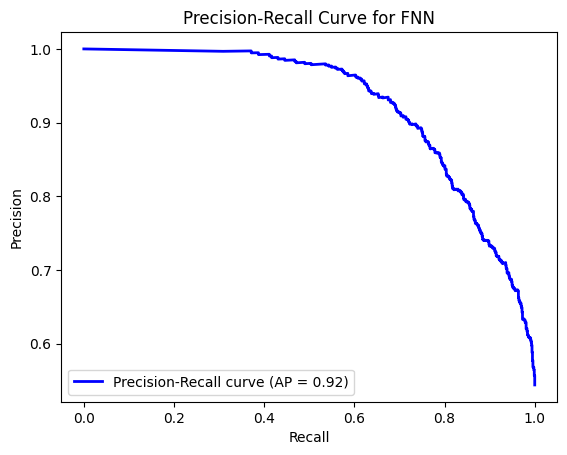

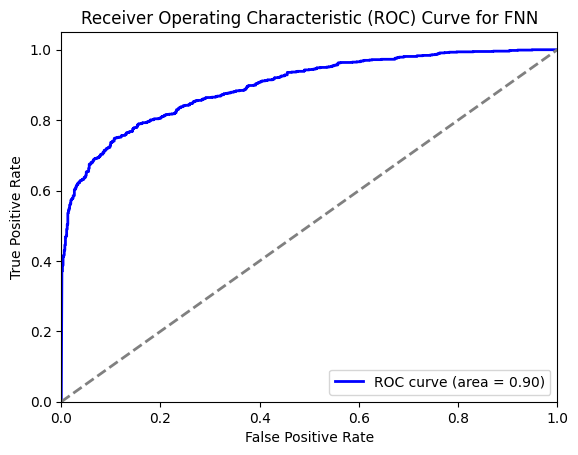

In [153]:
# Plot Precision-Recall Curve
plt.figure()
plt.plot(fnn_recall_vals, fnn_precision_vals, color='blue', lw=2, label=f'Precision-Recall curve (AP = {fnn_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for FNN')
plt.legend(loc="lower left")
plt.show()

# Plot ROC AUC Curve
plt.figure()
plt.plot(fnn_fpr, fnn_tpr, color='blue', lw=2, label=f'ROC curve (area = {fnn_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for FNN')
plt.legend(loc="lower right")
plt.show()

Confusion Matrix:
[[745  89]
 [254 740]]


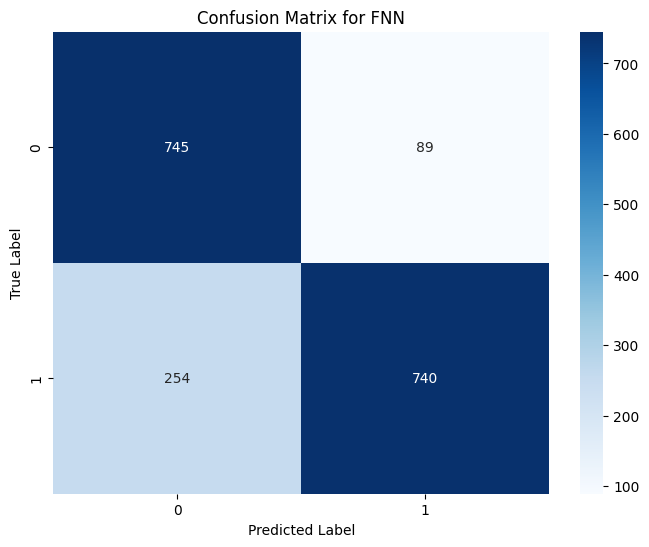

Classification report:
              precision    recall  f1-score   support

           0       0.75      0.89      0.81       834
           1       0.89      0.74      0.81       994

    accuracy                           0.81      1828
   macro avg       0.82      0.82      0.81      1828
weighted avg       0.83      0.81      0.81      1828



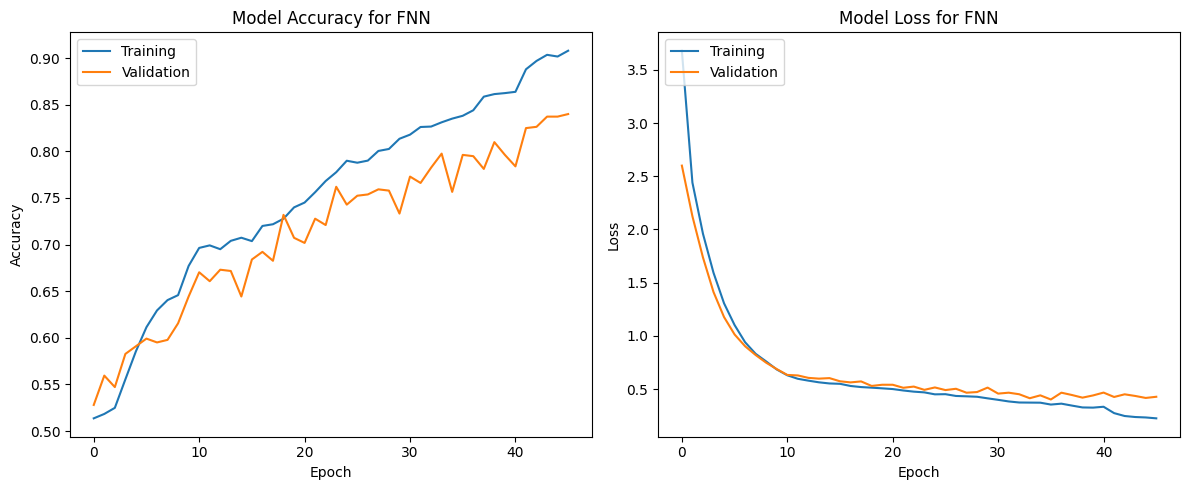

In [154]:
print("Confusion Matrix:")
print(fnn_cm)
plt.figure(figsize=(8, 6))
sns.heatmap(fnn_cm, annot=True, cmap='Blues', fmt='g')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for FNN')
plt.show()

print("Classification report:")
print(fnn_cr)

# Plotting the training and validation accuracy and loss
def plot_training_history(history):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy for FNN')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='upper left')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss for FNN')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

# Plot the training history
plot_training_history(fnn_history)

## CNN

In [38]:
print("CNN model:")
print("Accuracy: ", cnn_accuracy)
print("Precision: ", cnn_precision)
print("Recall: ", cnn_recall)
print("F1 score: ", cnn_f1)
print("Specificity: ", cnn_specificity)
print("AUC-ROC:", cnn_roc_auc)

CNN model:
Accuracy:  0.899343544857768
Precision:  0.9115853658536586
Recall:  0.9024144869215291
F1 score:  0.9069767441860466
Specificity:  0.89568345323741
AUC-ROC: 0.9714799588900307


In [39]:
print("cnn_avg_precision: ", cnn_avg_precision)
print("cnn_fpr: ", cnn_fpr)
print("cnn_tpr: ", cnn_tpr)
print("cnn_thresholds: ", cnn_thresholds)
print("cnn_precision_vals: ", cnn_precision_vals)
print("cnn_recall_vals: ", cnn_recall_vals)
print("cnn_pr_thresholds: ", cnn_pr_thresholds)

cnn_avg_precision:  0.9784390534095484
cnn_fpr:  [0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.00239808 0.00239808 0.00359712 0.00359712 0.00479616
 0.00479616 0.0059952  0.0059952  0.00719424 0.00719424 0.00839329
 0.00839329 0.00959233 0.00959233 0.01079137 0.01079137 0.01318945
 0.01318945 0.01438849 0.01438849 0.01558753 0.01558753 0.01798561
 0.01798561 0.01918465 0.01918465 0.02038369 0.02038369 0.02278177
 0.02278177 0.02398082 0.02398082 0.02517986 0.02517986 0.0263789
 0.0263789  0.02757794 0.02757794 0.03117506 0.03117506 0.0323741
 0.0323741  0.03357314 0.03357314 0.03477218 0.03477218 0.03597122
 0.03597122 0.03717026 0.03717026 0.0383693  0.0383693  0.03956835
 0.03956835 0.04076739 0.04076739 0.04196643 0.04196643 0.04316547
 0.04316547 0.04436451 0.04436451 0.04556355 0.04556355 0.04676259
 0.04676259 0.04916067 0.04916067 0.050

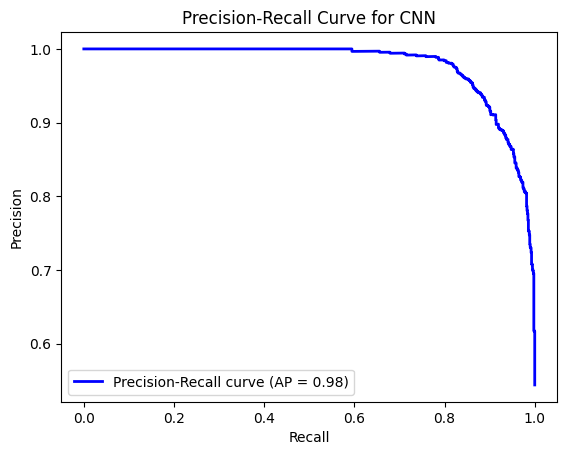

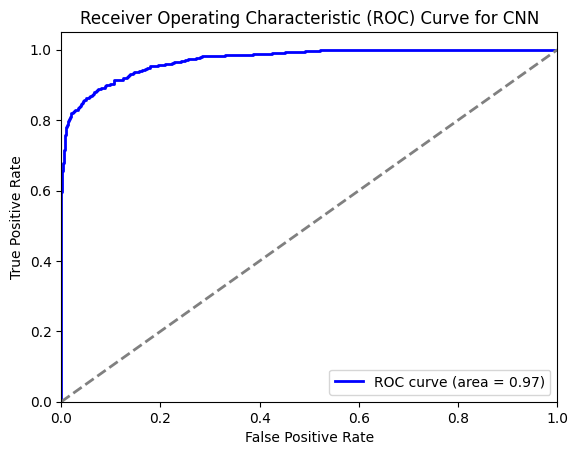

In [40]:
# Plot Precision-Recall Curve
plt.figure()
plt.plot(cnn_recall_vals, cnn_precision_vals, color='blue', lw=2, label=f'Precision-Recall curve (AP = {cnn_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for CNN')
plt.legend(loc="lower left")
plt.show()

# Plot ROC AUC Curve
plt.figure()
plt.plot(cnn_fpr, cnn_tpr, color='blue', lw=2, label=f'ROC curve (area = {cnn_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for CNN')
plt.legend(loc="lower right")
plt.show()

Confusion Matrix:
[[747  87]
 [ 97 897]]


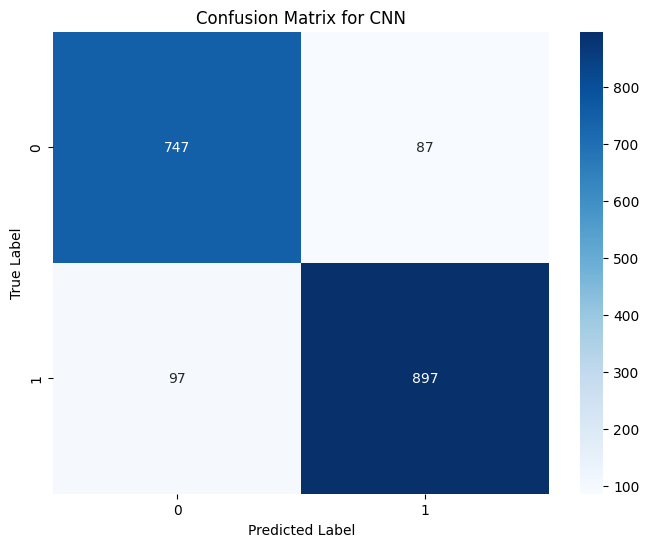

Classification report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       834
           1       0.91      0.90      0.91       994

    accuracy                           0.90      1828
   macro avg       0.90      0.90      0.90      1828
weighted avg       0.90      0.90      0.90      1828



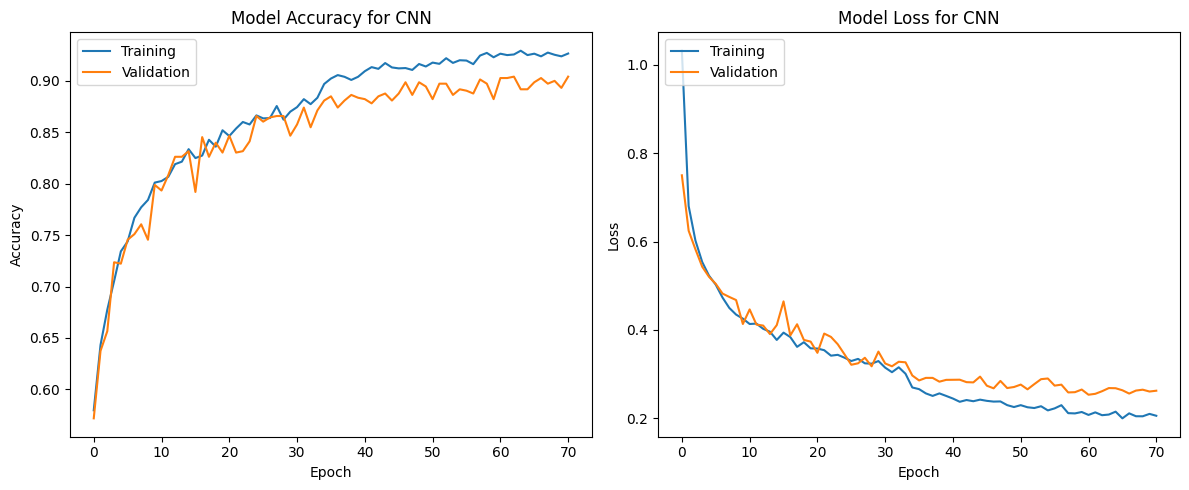

In [41]:
print("Confusion Matrix:")
print(cnn_cm)
plt.figure(figsize=(8, 6))
sns.heatmap(cnn_cm, annot=True, cmap='Blues', fmt='g')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for CNN')
plt.show()

print("Classification report:")
print(cnn_cr)

# Plotting the training and validation accuracy and loss
def plot_training_history(history):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy for CNN')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='upper left')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss for CNN')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

# Plot the training history
plot_training_history(cnn_history)

## LSTM

In [30]:
print("LSTM model:")
print("Accuracy: ", lstm_accuracy)
print("Precision: ", lstm_precision)
print("Recall: ", lstm_recall)
print("F1 score: ", lstm_f1)
print("Specificity: ", lstm_specificity)
print("AUC-ROC:", lstm_roc_auc)

LSTM model:
Accuracy:  0.8736323851203501
Precision:  0.8896833503575077
Recall:  0.8762575452716298
F1 score:  0.8829194120628484
Specificity:  0.8705035971223022
AUC-ROC: 0.9469744124217728


In [31]:
print("lstm_avg_precision: ", lstm_avg_precision)
print("lstm_fpr: ", lstm_fpr)
print("lstm_tpr: ", lstm_tpr)
print("lstm_thresholds: ", lstm_thresholds)
print("lstm_precision_vals: ", lstm_precision_vals)
print("lstm_recall_vals: ", lstm_recall_vals)
print("lstm_pr_thresholds: ", lstm_pr_thresholds)

lstm_avg_precision:  0.9541888024972193
lstm_fpr:  [0.         0.         0.         0.         0.         0.00119904
 0.00119904 0.00239808 0.00239808 0.00359712 0.00359712 0.00359712
 0.00359712 0.00479616 0.00479616 0.0059952  0.0059952  0.00719424
 0.00719424 0.00839329 0.00839329 0.00959233 0.00959233 0.01079137
 0.01079137 0.01199041 0.01199041 0.01318945 0.01318945 0.01438849
 0.01438849 0.01558753 0.01558753 0.01678657 0.01678657 0.01798561
 0.01798561 0.01918465 0.01918465 0.02158273 0.02158273 0.02278177
 0.02278177 0.02398082 0.02398082 0.02517986 0.02517986 0.0263789
 0.0263789  0.02757794 0.02757794 0.02877698 0.02877698 0.02997602
 0.02997602 0.03117506 0.03117506 0.0323741  0.0323741  0.03357314
 0.03357314 0.03477218 0.03477218 0.03597122 0.03597122 0.03717026
 0.03717026 0.0383693  0.0383693  0.03956835 0.03956835 0.04196643
 0.04196643 0.04316547 0.04316547 0.04436451 0.04436451 0.04556355
 0.04556355 0.04796163 0.04796163 0.04916067 0.04916067 0.05035971
 0.05035971 

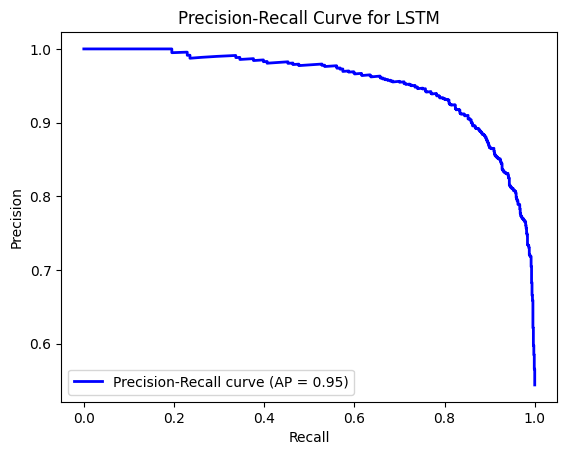

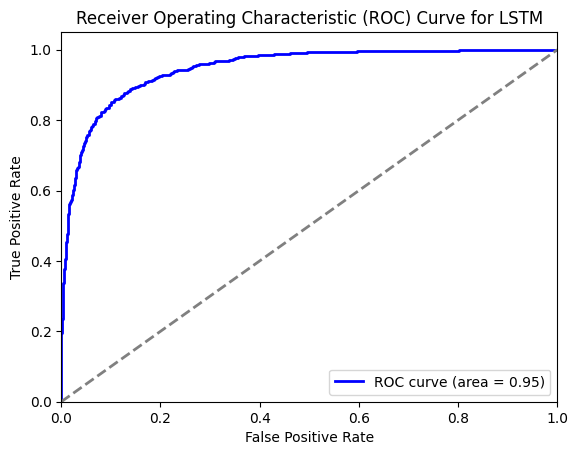

In [32]:
# Plot Precision-Recall Curve
plt.figure()
plt.plot(lstm_recall_vals, lstm_precision_vals, color='blue', lw=2, label=f'Precision-Recall curve (AP = {lstm_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for LSTM')
plt.legend(loc="lower left")
plt.show()

# Plot ROC AUC Curve
plt.figure()
plt.plot(lstm_fpr, lstm_tpr, color='blue', lw=2, label=f'ROC curve (area = {lstm_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for LSTM')
plt.legend(loc="lower right")
plt.show()

Confusion Matrix:
[[726 108]
 [123 871]]


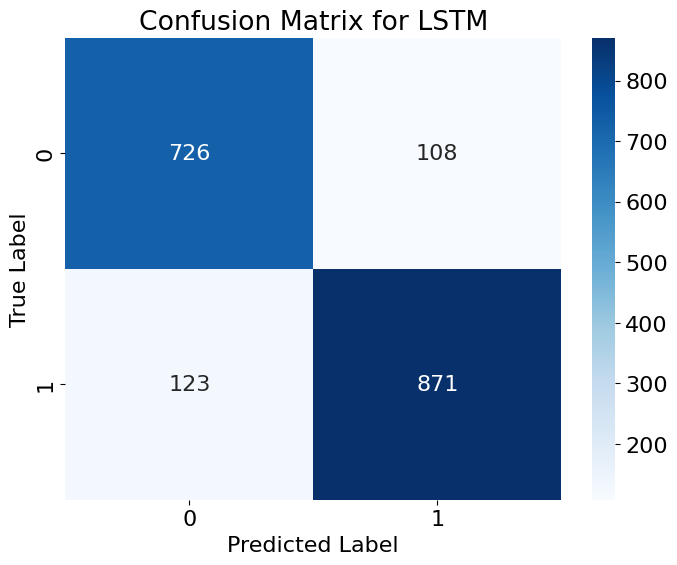

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.87      0.86       834
           1       0.89      0.88      0.88       994

    accuracy                           0.87      1828
   macro avg       0.87      0.87      0.87      1828
weighted avg       0.87      0.87      0.87      1828



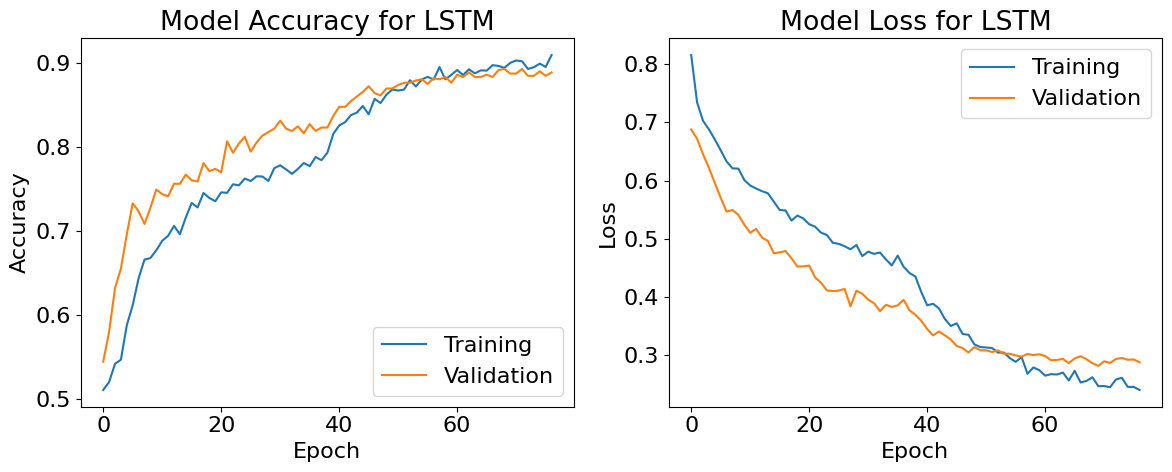

In [34]:
print("Confusion Matrix:")
print(lstm_cm)
plt.figure(figsize=(8, 6))
sns.heatmap(lstm_cm, annot=True, cmap='Blues', fmt='g')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for LSTM')
plt.show()

print("Classification report:")
print(lstm_cr)

# Plotting the training and validation accuracy and loss
def plot_training_history(history):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))
    #plt.rcParams.update({'font.size': 16})
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy for LSTM')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='lower right')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss for LSTM')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper right')

    plt.tight_layout()
    plt.show()

# Plot the training history
plot_training_history(lstm_history)

## Combined

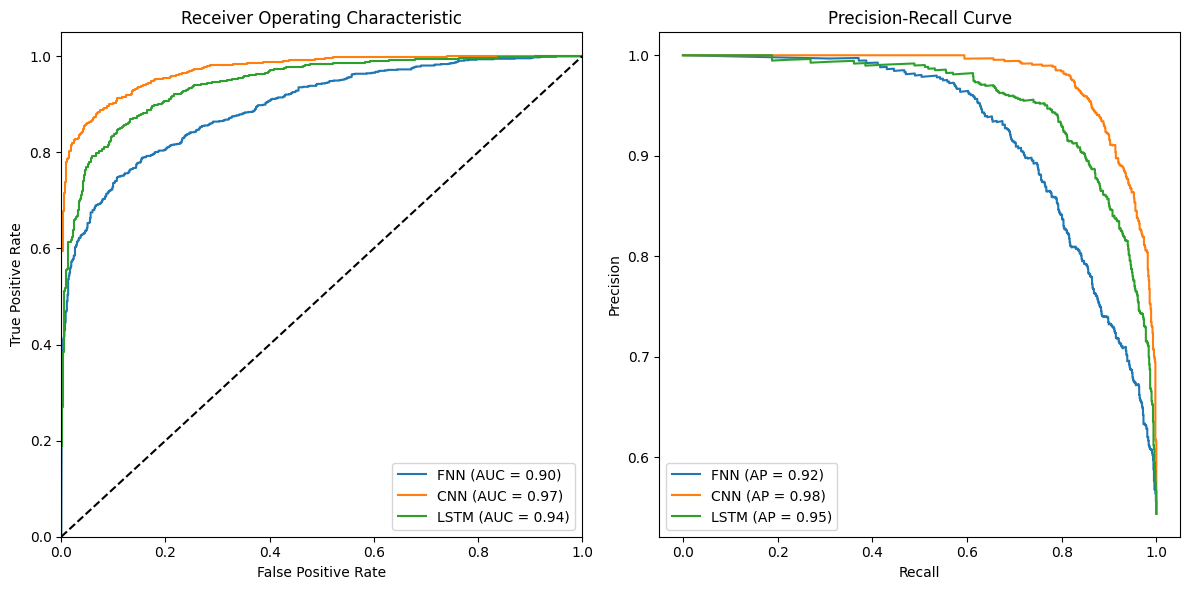

In [155]:
# Plot ROC curves
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(fnn_fpr, fnn_tpr, label=f'FNN (AUC = {fnn_roc_auc:.2f})')
plt.plot(cnn_fpr, cnn_tpr, label=f'CNN (AUC = {cnn_roc_auc:.2f})')
plt.plot(lstm_fpr, lstm_tpr, label=f'LSTM (AUC = {lstm_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")

# Plot Precision-Recall curves
plt.subplot(1, 2, 2)
plt.plot(fnn_recall_vals, fnn_precision_vals, label=f'FNN (AP = {fnn_avg_precision:.2f})')
plt.plot(cnn_recall_vals, cnn_precision_vals, label=f'CNN (AP = {cnn_avg_precision:.2f})')
plt.plot(lstm_recall_vals, lstm_precision_vals, label=f'LSTM (AP = {lstm_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")

plt.tight_layout()
plt.show()

In [ ]:
%%shell
jupyter nbconvert --to html /content/stress_detection.ipynb

[NbConvertApp] Converting notebook /content/stress_detection.ipynb to html
[NbConvertApp] Writing 1435069 bytes to /content/stress_detection.html
